In [1]:
import pandas as pd
print(pd.__version__)

3.0.6


In [2]:
from pathlib import Path

DATA_DIR = Path("../data/processed/sql_exports")

print("Folder exists:", DATA_DIR.exists())
print("\nFiles found:")

for file in sorted(DATA_DIR.glob("*.csv")):
    print(f"{file.name} — {file.stat().st_size:,} bytes")

Folder exists: True

Files found:
category_performance.csv — 3,604 bytes
delivery_performance.csv — 102 bytes
monthly_sales.csv — 1,242 bytes
payment_performance.csv — 261 bytes
review_performance.csv — 97 bytes
state_performance.csv — 923 bytes


In [3]:

from pathlib import Path
import pandas as pd

DATA_DIR = Path("../data/processed/sql_exports")

files = {
    "monthly_sales": "monthly_sales.csv",
    "category_performance": "category_performance.csv",
    "delivery_performance": "delivery_performance.csv",
    "payment_performance": "payment_performance.csv",
    "review_performance": "review_performance.csv",
    "state_performance": "state_performance.csv",
}

sql_results = {}

for name, filename in files.items():
    sql_results[name] = pd.read_csv(DATA_DIR / filename)
    print(f"{name}: {sql_results[name].shape[0]} rows, "
          f"{sql_results[name].shape[1]} columns")

print("\nMonthly sales preview:")
display(sql_results["monthly_sales"].head())


monthly_sales: 24 rows, 6 columns
category_performance: 74 rows, 5 columns
delivery_performance: 1 rows, 4 columns
payment_performance: 5 rows, 5 columns
review_performance: 1 rows, 4 columns
state_performance: 27 rows, 5 columns

Monthly sales preview:


,month,total_orders,total_items,product_revenue,freight_revenue,total_revenue
0,2016-09-01,3,6,267.36,87.39,354.75
1,2016-10-01,308,363,49507.66,7301.18,56808.84
2,2016-12-01,1,1,10.90,8.72,19.62
3,2017-01-01,789,955,120312.87,16875.62,137188.49
4,2017-02-01,1733,1951,247303.02,38977.60,286280.62


In [4]:

# Check the quality of every SQL export

for name, df in sql_results.items():
    print(f"\n--- {name} ---")
    print("Shape:", df.shape)
    print("Duplicate rows:", df.duplicated().sum())
    print("Missing values:", df.isna().sum().sum())
    print("Columns:", df.columns.tolist())

# Check the monthly sales timeline
monthly = sql_results["monthly_sales"].copy()
monthly["month"] = pd.to_datetime(monthly["month"])

print("\nMonthly sales date range:")
print("First month:", monthly["month"].min())
print("Last month:", monthly["month"].max())

print("\nMonths in chronological order:")
display(monthly[["month", "total_orders", "total_revenue"]])



--- monthly_sales ---
Shape: (24, 6)
Duplicate rows: 0
Missing values: 0
Columns: ['month', 'total_orders', 'total_items', 'product_revenue', 'freight_revenue', 'total_revenue']

--- category_performance ---
Shape: (74, 5)
Duplicate rows: 0
Missing values: 0
Columns: ['product_category', 'items_sold', 'product_revenue', 'freight_revenue', 'total_revenue']

--- delivery_performance ---
Shape: (1, 4)
Duplicate rows: 0
Missing values: 0
Columns: ['delivered_orders', 'late_deliveries', 'late_delivery_percentage', 'average_delivery_days']

--- payment_performance ---
Shape: (5, 5)
Duplicate rows: 0
Missing values: 0
Columns: ['payment_type', 'payment_records', 'orders_paid', 'total_payment_value', 'average_payment_value']

--- review_performance ---
Shape: (1, 4)
Duplicate rows: 0
Missing values: 0
Columns: ['average_review_score', 'total_reviews', 'low_score_reviews', 'low_score_percentage']

--- state_performance ---
Shape: (27, 5)
Duplicate rows: 0
Missing values: 0
Columns: ['customer_

,month,total_orders,total_revenue
0,2016-09-01,3,354.75
1,2016-10-01,308,56808.84
2,2016-12-01,1,19.62
3,2017-01-01,789,137188.49
4,2017-02-01,1733,286280.62
5,2017-03-01,2641,432048.59
6,2017-04-01,2391,412422.24
7,2017-05-01,3660,586190.95
8,2017-06-01,3217,502963.04
9,2017-07-01,3969,584971.62


In [5]:

# Check which calendar months are missing

monthly = monthly.sort_values("month").copy()

all_months = pd.date_range(
    start=monthly["month"].min(),
    end=monthly["month"].max(),
    freq="MS"
)

missing_months = all_months.difference(monthly["month"])

print("Number of months in calendar range:", len(all_months))
print("Number of months in SQL export:", len(monthly))
print("Missing months:", len(missing_months))

for month in missing_months:
    print(month.strftime("%Y-%m"))

# Inspect the first and last months
print("\nFirst 3 months:")
display(monthly[["month", "total_orders", "total_revenue"]].head(3))

print("\nLast 3 months:")
display(monthly[["month", "total_orders", "total_revenue"]].tail(3))


Number of months in calendar range: 25
Number of months in SQL export: 24
Missing months: 1
2016-11

First 3 months:


,month,total_orders,total_revenue
0,2016-09-01,3,354.75
1,2016-10-01,308,56808.84
2,2016-12-01,1,19.62



Last 3 months:


,month,total_orders,total_revenue
21,2018-07-01,6273,1058728.03
22,2018-08-01,6452,1003308.47
23,2018-09-01,1,166.46


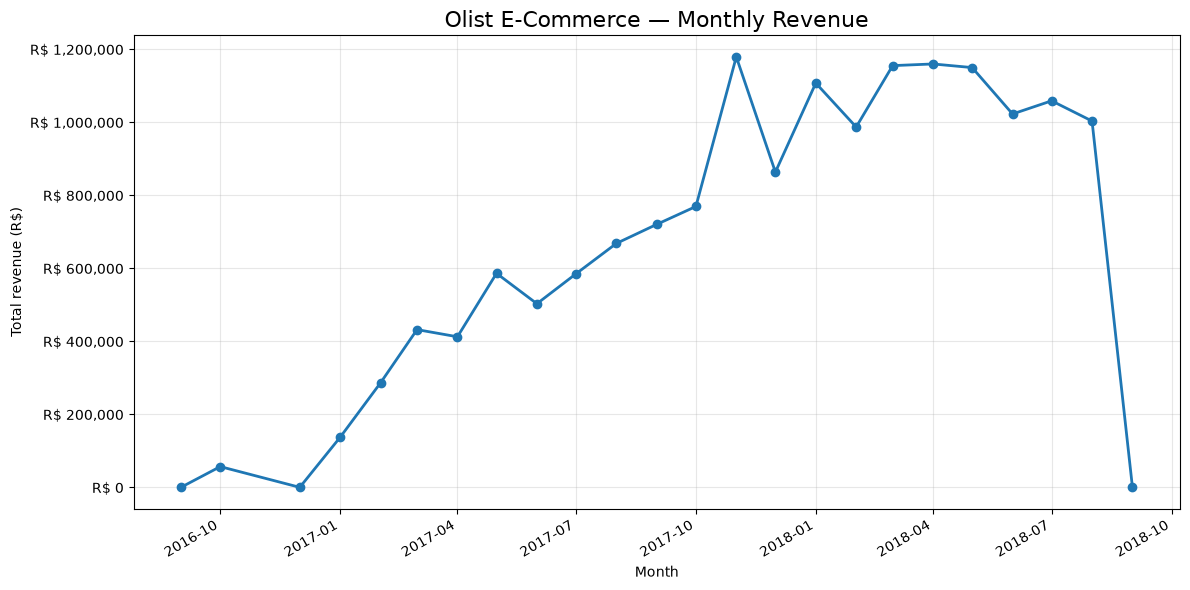

In [6]:

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# Work on a copy; do not modify the original SQL results
monthly_chart = monthly.copy()

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    monthly_chart["month"],
    monthly_chart["total_revenue"],
    marker="o",
    linewidth=2
)

ax.set_title("Olist E-Commerce — Monthly Revenue", fontsize=16)
ax.set_xlabel("Month")
ax.set_ylabel("Total revenue (R$)")
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"R$ {x:,.0f}")
)

ax.grid(True, alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()

# Save the chart for your portfolio report
output_dir = Path("../reports/figures")
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "monthly_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [7]:
print("Last purchase date in the original orders table:")

orders = pd.read_csv("../data/raw/olist_orders_dataset.csv")

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    errors="coerce"
)

print(orders["order_purchase_timestamp"].max())

Last purchase date in the original orders table:
2018-10-17 17:30:18


In [9]:
from pathlib import Path
import pandas as pd

# Load the SQL export
DATA_DIR = Path("../data/processed/sql_exports")

monthly_sales = pd.read_csv(DATA_DIR / "monthly_sales.csv")

# Convert the month column to datetime
monthly_sales["month"] = pd.to_datetime(monthly_sales["month"])

# Display the last five months
print(monthly_sales.tail(5).to_string(index=False))

     month  total_orders  total_items  product_revenue  freight_revenue  total_revenue
2018-05-01          6853         7925        996517.68        153264.14     1149781.82
2018-06-01          6160         7078        865124.31        157552.80     1022677.11
2018-07-01          6273         7092        895507.22        163220.81     1058728.03
2018-08-01          6452         7248        854686.33        148622.14     1003308.47
2018-09-01             1            1           145.00            21.46         166.46


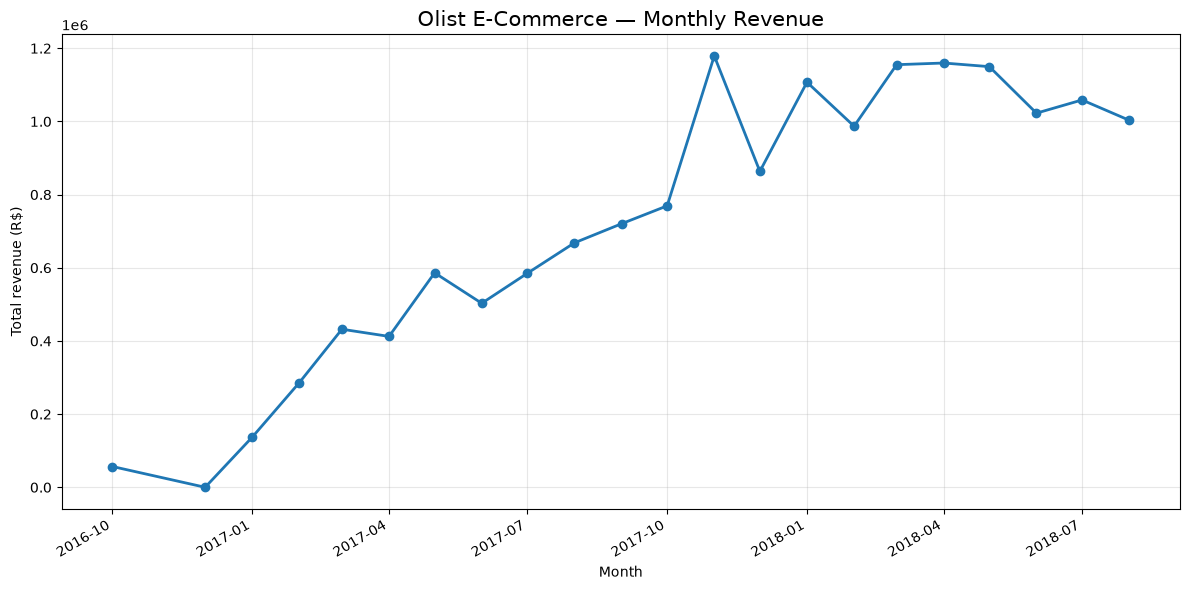

In [10]:

import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# Keep the full monthly_sales DataFrame unchanged
chart_data = monthly_sales.copy()
chart_data["month"] = pd.to_datetime(chart_data["month"])

# Select the main reporting period
chart_data = chart_data[
    (chart_data["month"] >= "2016-10-01") &
    (chart_data["month"] <= "2018-08-01")
].sort_values("month")

# Create the chart
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    chart_data["month"],
    chart_data["total_revenue"],
    marker="o",
    linewidth=2
)

ax.set_title("Olist E-Commerce — Monthly Revenue", fontsize=15)
ax.set_xlabel("Month")
ax.set_ylabel("Total revenue (R$)")
ax.grid(True, alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()

# Save the chart
output_dir = Path("../reports/figures")
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "monthly_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [11]:
from pathlib import Path

chart_path = Path("../reports/figures/monthly_revenue.png")

print("Chart exists:", chart_path.exists())

if chart_path.exists():
    print("File size:", chart_path.stat().st_size, "bytes")

Chart exists: True
File size: 190519 bytes
